In [18]:
from dataclasses import dataclass, field
from pytorch_tabnet.tab_model import TabNetRegressor
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.metrics import make_scorer, mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import FunctionTransformer

from torch.optim.lr_scheduler import StepLR
from sqlalchemy import create_engine
from urllib.parse import quote_plus
import os
from datetime import datetime
import pandas as pd
import numpy as np
import torch
import requests
import random
from requests.auth import HTTPBasicAuth
import json
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from openpyxl import Workbook
from openpyxl.styles import PatternFill, Alignment
from matplotlib import pyplot as plt

from utils import dictionaries as dictionary
import utils.prediction_utils as pred

In [19]:
TEST_START_DATE = '2024-10-01'

TARGET = 'ster_1+_total'
TARGET_GROUP = '25-67'

NUMERICAL_COLS = ['npo1_grp_daynight', 'npo1_grp_primetime',
                  'npo2_grp_daynight', 'npo2_grp_primetime',
                  'npo3_grp_daynight', 'npo3_grp_primetime',
                  'regio_grp_daynight', 'regio_grp_primetime',
                  'timef_olympic_period_overlap', 'timef_football_period_overlap',
                  'timef_duration_days',
                  # 'timef_start_month', 'timef_end_month',
                  'timef_start_year',
                  # 'timef_end_year',
                  'timef_start_week',
                  # 'timef_end_week',
                  # 'timef_end_day',
                  # 'timef_start_day'
                ]

CATEGORICAL_COLS = [
                    # 'timef_start_season',
                    # 'timef_end_season'
                    ]

BOOLEAN_COLS = [
                'alcohol_kansspelen',
                'is_olympic_period',
                'is_football_period',
                # 'new_data'
                ]

FEATURES = NUMERICAL_COLS + CATEGORICAL_COLS + BOOLEAN_COLS


In [ ]:
@dataclass
class TabNetModel:
    df: pd.DataFrame = None
    target: str = TARGET
    features: list = field(default_factory=lambda: FEATURES)
    numerical_cols: list = field(default_factory=lambda: NUMERICAL_COLS)
    categorical_cols: list = field(default_factory=lambda: CATEGORICAL_COLS)
    boolean_cols: list = field(default_factory=lambda: BOOLEAN_COLS)
    target_group: str = TARGET_GROUP
    n_d: int = 32
    n_a: int = 32
    n_steps: int = 3
    gamma: float = 1.5
    learning_rate: float = 0.01
    lambda_sparse: float = 0.01
    mask_type: str = 'sparsemax'
    max_epochs: int = 20
    patience: int = 10
    batch_size: int = 128
    virtual_batch_size: int = 128
    param_grid: dict = field(default_factory=lambda: {
            'n_d': [16, 32],
            'n_a': [16, 32],
            'n_steps': [5, 7],
            'gamma': [1.5, 2.0],
            'learning_rate': [0.03, 0.05, 0.07],
            'lambda_sparse': [0.001, 0.005, 0.01],
            'mask_type': ['sparsemax', 'entmax'],
        })

    best_params_old: dict = field(default_factory=dict)
    best_params_new: dict = field(default_factory=dict)
    scaler: StandardScaler = field(default_factory=StandardScaler)
    encoder: OneHotEncoder = field(default_factory=lambda: OneHotEncoder(drop='first', sparse_output=False))
    preprocessor: ColumnTransformer = field(init=False)
    model: TabNetRegressor = field(init=False)

    test_start_date: str = TEST_START_DATE
    train_data: pd.DataFrame = field(init=False)
    val_data: pd.DataFrame = field(init=False)
    test_data: pd.DataFrame = field(init=False)

    X_train: np.ndarray = field(init=False)
    y_train: np.ndarray = field(init=False)
    X_val: np.ndarray = field(init=False)
    y_val: np.ndarray = field(init=False)
    X_test: np.ndarray = field(init=False)
    y_test: np.ndarray = field(init=False)

    def __post_init__(self):
        if self.df is None and self.target_group:
            query = self.construct_query()
            self.df = self.query_to_df(query)
            self.df = self.prepare_data(self.df)
        self.model = self.initialize_model()  # Ensure that initialize_model sets up `self.model`
        self.create_preprocessor()

    def initialize_model(self):
        return TabNetRegressor(
            n_d=self.n_d,
            n_a=self.n_a,
            n_steps=self.n_steps,
            gamma=self.gamma,
            optimizer_fn=torch.optim.Adam,
            optimizer_params=dict(lr=self.learning_rate),
            scheduler_fn=StepLR,
            scheduler_params={"step_size": 15, "gamma": 0.5},
            mask_type=self.mask_type,
            lambda_sparse=self.lambda_sparse,
            seed = 42
        )

    def construct_query(self):
        target_group_str = f"'{self.target_group}'"
        query = f'''
            SELECT b.flight_id,
                   b.target_group,
                   f.advertiser,
                   f.product,
                   f.start_date,
                   f.end_date,
                   b.campaign_duration,
                   b.daypart,
                   f.mock_campaign,
                   f.alcohol_kansspelen,
                   b.ster_grp,
                   b.regio_grp,
                   b.npo1_grp,
                   b.npo2_grp,
                   b.npo3_grp,
                   b.[ster_1+]
            FROM [dbo].[tv.bereik_ster] b
            LEFT JOIN [dbo].[tv.flights_ster] f ON b.flight_id = f.flight_id
            WHERE b.ster_grp > 0
            AND target_group IN ({target_group_str})
            --AND b.campaign_duration > 7
            --AND NOT (YEAR(start_date) = 2024 AND MONTH(start_date) IN (6, 7, 8))
            ORDER BY start_date;
        '''
        return query

    def create_sql_alchemy_engine(self):
        """
        Creates and returns a SQLAlchemy engine for connecting to a SQL Server database.
        """
        quoted = quote_plus(
            "Driver={ODBC+Driver+17+for+SQL+Server};"
            "Server=tcp:stercampsql.database.windows.net;"
            "Database=SterCampNew;"
            "uid=stercampadmin;"
            f"pwd={os.getenv('SQLDB')}"
        )
        alchemy_con = f"mssql+pyodbc:///?odbc_connect={quoted}"
        engine = create_engine(alchemy_con)
        return engine

    def query_to_df(self, query):
        engine = self.create_sql_alchemy_engine()
        df = pd.read_sql_query(query, engine)
        return df

    def prepare_data(self, df):
        df = df[["flight_id", "target_group", "start_date", "end_date", "advertiser", "product", "daypart", "mock_campaign", "alcohol_kansspelen",
                        "npo1_grp", "npo2_grp", "npo3_grp", "regio_grp", "ster_grp",
                        "ster_1+"]].reset_index(drop=True)

        df = (df.pivot_table(index=["flight_id", "target_group", "start_date", "end_date", 'advertiser', 'product', "mock_campaign", "alcohol_kansspelen"],
                            columns='daypart', fill_value=0.0,
                            values=['npo1_grp', 'npo2_grp', 'npo3_grp',
                                    'ster_grp', 'ster_1+', 'regio_grp'], aggfunc='sum').reset_index())


        df.columns = ["_".join(col) if col[1] else col[0] for col in df.columns.to_flat_index()]

        # Convert start_date and end_date to datetime objects and calculate required values
        df['start_date'] = pd.to_datetime(df['start_date'], format="%d%m%y", errors='coerce')
        df['end_date'] = pd.to_datetime(df['end_date'], format="%d%m%y", errors='coerce')

        # Apply function to create extra columns
        df['timef_start_month'] = df['start_date'].dt.month
        df['timef_end_month'] = df['end_date'].dt.month
        df['timef_start_year'] = df['start_date'].dt.year
        df['timef_end_year'] = df['end_date'].dt.year
        df['timef_start_week'] = df['start_date'].dt.strftime("%V").astype(int)
        df['timef_end_week'] = df['end_date'].dt.strftime("%V").astype(int)
        df['timef_start_day'] = df['start_date'].dt.day
        df['timef_end_day'] = df['end_date'].dt.day
        df['timef_duration_days'] = df.apply(lambda row: (row['end_date'] - row['start_date']).days + 1, axis=1)

        df['timef_start_season'] = df['timef_start_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                      'Spring' if month in [3, 4, 5] else
                                                      'Summer' if month in [6, 7, 8] else
                                                      'Autumn')
        df['timef_end_season'] = df['timef_end_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                    'Spring' if month in [3, 4, 5] else
                                                    'Summer' if month in [6, 7, 8] else
                                                    'Autumn')

        # Calculate total overlap with olympics and WK/EK
        df['timef_olympic_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.olympic_period_list))
        df['timef_football_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.football_wk_ek_list))

        # Create interaction features
        df['grp_olympic_overlap'] = df['ster_grp_total'] * df['timef_olympic_period_overlap']
        df['grp_football_overlap'] = df['ster_grp_total'] * df['timef_football_period_overlap']

        # Create binary indicators
        df['is_olympic_period'] = (df['timef_olympic_period_overlap'] > 0).astype(int)
        df['is_football_period'] = (df['timef_football_period_overlap'] > 0).astype(int)

        # Create a new column 'new_data' indicating old or new
        df['new_data'] = pd.cut(
            df['start_date'],
            bins=[pd.Timestamp.min, pd.to_datetime('2023-09-01'), pd.Timestamp.max],
            labels=[0, 1])

        # Add n random rows that have a base value of 0 GRPs and bereik
        non_grp_columns = ['start_date', 'end_date', 'timef_duration_days', 'timef_olympic_period_overlap', 'timef_football_period_overlap',
                            'timef_start_day', 'timef_end_day', 'timef_start_week', 'timef_end_week', 'timef_start_month',
                            'timef_end_month', 'timef_start_year', 'timef_end_year', 'timef_start_season', 'timef_end_season',
                            'target_group', 'advertiser', 'product', 'mock_campaign', 'alcohol_kansspelen', 'new_data']

        # Sample 600 random rows with 0 GRPs and bereik
        sampled_df = df.sample(n=600, random_state=42).reset_index(drop=True)
        sampled_df_zeroed = sampled_df.copy()
        for column in sampled_df_zeroed.columns:
            if column not in non_grp_columns:
                sampled_df_zeroed[column] = 0

        df_combined = pd.concat([df, sampled_df_zeroed], ignore_index=True)

        df = df_combined.sort_values(by=['start_date', 'advertiser', 'product', 'end_date'])

        ########## Filter Outliers ##########

        q_low = df['ster_grp_total'].quantile(0.01)
        q_hi  = df['ster_grp_total'].quantile(0.99)
        df = df[(df['ster_grp_total'] < q_hi) & (df['ster_grp_total'] > q_low)]

        q_low = df['ster_1+_total'].quantile(0.01)
        q_hi  = df['ster_1+_total'].quantile(0.99)
        df = df[(df['ster_1+_total'] < q_hi) & (df['ster_1+_total'] > q_low)]

        return df

    def split_data_by_date(self, start_date, end_date, split_ratio=0.8):
        """
        Splits data within a specified date range into training and validation sets.

        Parameters:
        - start_date (str): The start date for filtering data.
        - end_date (str): The end date for filtering data.
        - split_ratio (float): The ratio to split training data within the range (default is 0.8).

        Returns:
        - train_data: Training data within the date range.
        - val_data: Validation data within the date range.
        """
        # Filter data within the specified date range
        data_in_range = self.df[(self.df['start_date'] >= start_date) & (self.df['start_date'] <= end_date)]

        # Calculate the split index for chronological split
        split_index = int(split_ratio * len(data_in_range))

        # Split into training and validation sets
        train_data = data_in_range.iloc[:split_index]
        val_data = data_in_range.iloc[split_index:]
        return train_data, val_data

    def create_preprocessor(self):
        transformers = []

        # Adding a scaler to the numerical transformer pipeline
        numerical_transformer_steps = [
            ('imputer', SimpleImputer(strategy='mean')),
            ('scaler', StandardScaler())  # Add the scaler here
        ]
        numerical_transformer = Pipeline(steps=numerical_transformer_steps)
        transformers.append(('num', numerical_transformer, self.numerical_cols))

        if self.categorical_cols:
            categorical_transformer = Pipeline(steps=[
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
            ])
            transformers.append(('cat', categorical_transformer, self.categorical_cols))

        if self.boolean_cols:
            boolean_transformer = Pipeline(steps=[
                ('int_conversion', FunctionTransformer(lambda x: x.astype(int), validate=False)),
                ('imputer', SimpleImputer(strategy='most_frequent'))
            ])
            transformers.append(('bool', boolean_transformer, self.boolean_cols))

        # Create the ColumnTransformer
        self.preprocessor = ColumnTransformer(transformers=transformers)

    def get_feature_names(self, preprocessor):
        feature_names = []

        # Get numerical feature names
        if 'num' in preprocessor.named_transformers_:
            feature_names += self.numerical_cols

        # Get categorical feature names
        if 'cat' in preprocessor.named_transformers_:
            encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
            cat_feature_names = encoder.get_feature_names_out(self.categorical_cols)
            feature_names += cat_feature_names.tolist()

        # Get boolean feature names
        if 'bool' in preprocessor.named_transformers_:
            feature_names += self.boolean_cols

        self.feature_names = feature_names

        return feature_names

    def fit_preprocessor(self, train_data):
        # Define and fit the preprocessor only on the old training data
        preprocessor = ColumnTransformer(
            transformers=[
                ('num', self.scaler, NUMERICAL_COLS),
                ('cat', self.encoder, CATEGORICAL_COLS),
                ('bool', FunctionTransformer(lambda x: x.astype(int)), BOOLEAN_COLS)
            ],
            remainder='passthrough'
        )
        preprocessor.fit(train_data[self.features])
        return preprocessor

    def _transform(self, data):
        """
        Transforms the given dataset using the pre-fitted preprocessor.

        Parameters:
        - data (DataFrame): Dataset to transform.

        Returns:
        - X_transformed: Transformed feature matrix
        - y: Target array
        """
        # Extract features and target
        print(f"Transforming data with shape: {data.shape}")
        X = data[self.features]
        y = data[self.target].values.reshape(-1, 1)

        # Transform features
        X_transformed = self.preprocessor.transform(X)

        return np.array(X_transformed), y

    def prepare_old_data(self):
        """
        Prepares the old data (2018 to 09-2023) by fitting the preprocessor on old training data
        and transforming both training and validation data.
        """
        # Step 1: Split data into training and validation sets
        train_data, val_data = self.split_data_by_date(start_date='2018-01-01', end_date='2023-09-01')

        # Step 2: Fit the preprocessor on the training data
        print("Fitting the preprocessor on the old training data...")
        self.preprocessor.fit(train_data[self.features])
        self.feature_names = self.get_feature_names(self.preprocessor)

        # Step 3: Transform training and validation sets
        print("Transforming old training data...")
        self.X_train, self.y_train = self._transform(train_data)

        print("Transforming old validation data...")
        self.X_val, self.y_val = self._transform(val_data)

    def prepare_new_data(self):
        """
        Prepares the new data (09-2023 to 10-2024) by reusing the fitted preprocessor
        from old data and transforming the new training, validation, and test sets.
        """
        # Define dates for new data
        self.train_data, self.val_data = self.split_data_by_date(start_date='2023-09-01', end_date='2024-09-30')
        self.test_data = self.df[self.df['start_date'] >= self.test_start_date]

        # Step 1: Transform new training, validation, and test sets using the pre-fitted preprocessor
        self.X_train, self.y_train = self._transform(self.train_data)
        self.X_val, self.y_val = self._transform(self.val_data)
        self.X_test, self.y_test = self._transform(self.test_data)

    def tune_model(self, patience = 10, max_epochs = 25):
        """
        Perform time-lapse cross-validation for hyperparameter tuning while retaining knowledge between folds.
        Uses preprocessed training data from `self.X_train` and `self.y_train`.

        Returns:
        - best_params: Best hyperparameters based on cross-validation performance.
        """
        from itertools import product
        from sklearn.model_selection import TimeSeriesSplit
        from sklearn.metrics import mean_squared_error
        import numpy as np

        tscv = TimeSeriesSplit(n_splits=3)
        best_params = None
        best_score = float('inf')
        param_grid = self.param_grid

        # Generate all combinations of parameters
        param_names = list(param_grid.keys())
        param_combinations = list(product(*param_grid.values()))

        for params in param_combinations:
            params_dict = dict(zip(param_names, params))
            print(f"Testing parameters: {params_dict}")

            # Extract and handle learning_rate separately
            learning_rate = params_dict.pop('learning_rate')  # Remove from params
            params_dict['optimizer_params'] = {'lr': learning_rate}  # Add dynamically

            fold_scores = []
            self.model.set_params(**params_dict)  # Set hyperparameters for this run

            for train_index, val_index in tscv.split(self.X_train):
                # Split data into train and validation folds
                X_train_fold, X_val_fold = self.X_train[train_index], self.X_train[val_index]
                y_train_fold, y_val_fold = self.y_train[train_index], self.y_train[val_index]

                # Train on the training fold
                self.model.fit(
                    X_train_fold,
                    y_train_fold,
                    eval_set=[(X_val_fold, y_val_fold)],
                    patience=patience,  # Early stopping for tuning
                    max_epochs=max_epochs,  # Limit epochs during tuning
                )

                # Evaluate on the validation fold
                y_pred = self.model.predict(X_val_fold)
                fold_score = mean_squared_error(y_val_fold, y_pred)
                fold_scores.append(fold_score)

            # Calculate mean score across folds
            mean_score = np.mean(fold_scores)
            print(f"Mean CV score: {mean_score}")

            # Update best parameters if current score is better
            if mean_score < best_score:
                best_score = mean_score
                best_params = params_dict

        print(f"Best parameters: {best_params}, Best score: {best_score}")
        return best_params

    def train_model(self, best_params, max_epochs = 150, patience = 20, batch_size = 128, virtual_batch_size = 128):
        """
        Train the TabNet model on the full training set with the best hyperparameters.
        """
        self.model.set_params(**best_params)
        print("Models params:", self.model.get_params())
        # Train the model
        self.model.fit(
            X_train=self.X_train,
            y_train=self.y_train,
            eval_set=[(self.X_val, self.y_val)],
            eval_metric=['rmse'],
            max_epochs=max_epochs,
            patience=patience,
            batch_size=batch_size,
            virtual_batch_size=virtual_batch_size,
        )

        # Save training history in the class
        self.history = self.model.history  # Save history for later use

        # Extract training history
        history = self.model.history  # List of dicts containing 'loss' and eval metrics


        print("Training complete. Best epoch:", self.model.best_epoch)
        print("Best validation RMSE:", self.model.best_cost)
        print("Best Params:", best_params)

        # Plot training and validation curves
        epochs = range(len(history['loss']))
        plt.figure(figsize=(10, 6))

        # Plot training loss
        plt.plot(epochs, history['loss'], label='Training Loss')

        # Plot validation RMSE (key starts with 'val_' and metric is specified in eval_metric)
        plt.plot(epochs, history['val_0_rmse'], label='Validation RMSE')

        plt.xlabel('Epoch')
        plt.ylabel('Metric')
        plt.title('Training and Validation Curves')
        plt.legend()
        plt.grid(True)
        plt.show()

    def show_feature_importance(self):
        import matplotlib.pyplot as plt

        feature_importances  = self.model.feature_importances_
        # If you want to visualize feature importances with feature names
        feature_names = self.features  # Replace with your feature names list
        feature_importance_dict = dict(zip(feature_names, feature_importances))
        display("Feature Importances with Feature Names:", feature_importance_dict)

        # Sort feature importances in descending order
        sorted_importances = sorted(feature_importance_dict.items(), key=lambda x: x[1], reverse=True)
        features, importances = zip(*sorted_importances)

        # Plot
        plt.figure(figsize=(10, 6))
        plt.barh(features, importances)
        plt.xlabel("Importance")
        plt.title("Feature Importances from TabNet Model")
        plt.gca().invert_yaxis()
        plt.show()

    def display_metrics(self, y_train_true, y_train_pred, y_val_true, y_val_pred):
        """
        Display regression metrics (MAE, MSE, RMSE, R²) for both training and validation sets.

        Parameters:
        - y_train_true (array-like): True target values for the training set.
        - y_train_pred (array-like): Predicted target values for the training set.
        - y_val_true (array-like): True target values for the validation set.
        - y_val_pred (array-like): Predicted target values for the validation set.

        Returns:
        None (prints metrics directly)
        """
        # Training Metrics
        train_mae = mean_absolute_error(y_train_true, y_train_pred)
        train_mse = mean_squared_error(y_train_true, y_train_pred)
        train_rmse = np.sqrt(train_mse)
        train_r2 = r2_score(y_train_true, y_train_pred)

        # Validation Metrics
        val_mae = mean_absolute_error(y_val_true, y_val_pred)
        val_mse = mean_squared_error(y_val_true, y_val_pred)
        val_rmse = np.sqrt(val_mse)
        val_r2 = r2_score(y_val_true, y_val_pred)

        # Display Metrics
        print("Training Set Metrics:")
        print(f"  MAE: {train_mae:.4f}")
        print(f"  MSE: {train_mse:.4f}")
        print(f"  RMSE: {train_rmse:.4f}")
        print(f"  R²: {train_r2:.4f}")

        print("\nValidation Set Metrics:")
        print(f"  MAE: {val_mae:.4f}")
        print(f"  MSE: {val_mse:.4f}")
        print(f"  RMSE: {val_rmse:.4f}")
        print(f"  R²: {val_r2:.4f}")

        print("Best params old:", self.best_params_old)
        print("Best params new:", self.best_params_new)

    def predict_and_export_to_excel(self, file_path="test_predictions.xlsx"):
        """
        Predicts on self.test_data and exports the results, including target, prediction, and residuals, to an Excel file.

        Parameters:
        - file_path (str): The path to save the Excel file. Default is "test_predictions.xlsx".
        """
        print("Using:", type(self.model))

        # Ensure the model and data are available
        if not hasattr(self, "model") or self.model is None:
            raise ValueError("The model is not trained. Train the model before making predictions.")
        if not hasattr(self, "X_test") or self.X_test is None:
            raise ValueError("Test data is not available.")

        df_test = self.test_data.copy()

        # Predict on the test set
        predictions = self.model.predict(self.X_test)

        # Add predictions and residuals to the test dataframe
        df_test["prediction_nn"] = predictions
        df_test[self.target] = self.y_test.flatten()
        df_test["residual_nn"] = df_test[self.target] - df_test["prediction"]

        # Round the numerical values for better readability
        df_test[["prediction_nn", self.target, "residual_nn"]] = df_test[["prediction_nn", self.target, "residual_nn"]].round(2)

        # Select relevant columns
        df_test = df_test[[
            'flight_id', 'target_group', 'start_date', 'end_date', 'timef_duration_days', 'advertiser',
            'product', 'alcohol_kansspelen', 'npo1_grp_daynight',
            'npo1_grp_primetime', 'npo1_grp_total', 'npo2_grp_daynight',
            'npo2_grp_primetime', 'npo2_grp_total', 'npo3_grp_daynight',
            'npo3_grp_primetime', 'npo3_grp_total', 'regio_grp_daynight',
            'regio_grp_primetime', 'regio_grp_total', 'ster_grp_total',
            'ster_1+_total', 'prediction', 'residual'
        ]]

        # Calculate metrics
        test_mae = mean_absolute_error(self.y_test, predictions)
        test_mse = mean_squared_error(self.y_test, predictions)
        test_rmse = np.sqrt(test_mse)
        test_r2 = r2_score(self.y_test, predictions)

        # Display Metrics
        print("Test Set Metrics:")
        print(f"  MAE: {test_mae:.4f}")
        print(f"  MSE: {test_mse:.4f}")
        print(f"  RMSE: {test_rmse:.4f}")
        print(f"  R²: {test_r2:.4f}")

        # Use the format_excel function to format and save the Excel file
        self.format_excel(df_test, file_path)

    def format_excel(self, df, filename):
        # Create a new workbook
        wb = Workbook()
        ws = wb.active

        # Write column headers to the worksheet
        for col_index, column_name in enumerate(df.columns, start=1):
            ws.cell(row=1, column=col_index, value=column_name)

        # Write DataFrame data to the worksheet
        for row_index, row in enumerate(df.itertuples(index=False), start=2):  # Start from row 2 for data
            for col_index, value in enumerate(row, start=1):
                ws.cell(row=row_index, column=col_index, value=value)

        # Define colors for different thresholds
        light_red = PatternFill(start_color="FFC7CE", end_color="FFC7CE", fill_type="solid")
        medium_red = PatternFill(start_color="FF5733", end_color="FF5733", fill_type="solid")
        dark_red = PatternFill(start_color="B22222", end_color="B22222", fill_type="solid")

        light_blue = PatternFill(start_color="ADD8E6", end_color="ADD8E6", fill_type="solid")
        medium_blue = PatternFill(start_color="6495ED", end_color="6495ED", fill_type="solid")
        dark_blue = PatternFill(start_color="00008B", end_color="00008B", fill_type="solid")

        # Get the index of the 'residuals' column
        if 'residual' not in df.columns:
            raise ValueError("The DataFrame does not contain a 'residual' column.")
        res_col_index = df.columns.get_loc('residual') + 1  # Adding 1 because Excel uses 1-based indexing

        # Apply colors based on residuals
        for row in ws.iter_rows(min_row=2, min_col=res_col_index, max_row=ws.max_row, max_col=res_col_index):
            cell = row[0]
            if cell.value is not None:
                if cell.value >= 8:
                    cell.fill = dark_red
                elif cell.value >= 5:
                    cell.fill = medium_red
                elif cell.value >= 2:
                    cell.fill = light_red
                elif cell.value <= -8:
                    cell.fill = dark_blue
                elif cell.value <= -5:
                    cell.fill = medium_blue
                elif cell.value <= -2:
                    cell.fill = PatternFill(start_color='FFA8D0E6', end_color='FFA8D0E6', fill_type='solid')

        # Adjust column widths
        for col_index, column_name in enumerate(df.columns, start=1):
            col_letter = ws.cell(row=1, column=col_index).column_letter
            ws.column_dimensions[col_letter].width = max(len(column_name) + 2, 15)

        # Save the workbook
        wb.save(filename)
        print(f"Excel file saved as {filename}")

    def save_model(self, file_path):
        torch.save({
            'model_state_dict': self.state_dict(),
            'params': self.params,
        }, file_path)

        with open(f'{file_path}/tabnet_training_history.pkl', 'wb') as f:
            pickle.dump(self.model.history, f)

    def load_model(self, file_path):
        checkpoint = torch.load(file_path)
        self.load_state_dict(checkpoint['model_state_dict'])
        self.params = checkpoint['params']


In [21]:
# Create an instance of TabNetModel
model = TabNetModel()

c:\git\CampTvNew\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


## Test Data with API

In [ ]:
def get_api_token() -> str:
    req = requests.post(
        "https://auth.grouptechedge.com/connect/token",
        auth=HTTPBasicAuth("client.ster", os.getenv("EDGEAPI")),
        data={"grant_type": "client_credentials"},
    )
    token = json.loads(req.content)["access_token"]

    return token

def call_bereik_report_tv(
    target_group: str,
    start_date: str,
    end_date: str,
    token: str,
    advertiser=None,
    product=None,
) -> pd.DataFrame:
    """
    Call the camp bereik getter report API, retrieve the data for the specified target group, advertiser, product, start date, and end date, and return the result as a DataFrame.
    Advertiser and product aren't strictly nesssary, so the report can be called without these.

    Parameters:
    - target_group: the target group for the report
    - start_date: the start date in string format %d%m%y
    - end_date: the end date in string format %d%m%y
    - token: the authorization token for the API request
    - advertiser: the advertiser string
    - product: product string
    - only_ster: if True, only STER channels are included in the report
    """
    # target_group = dict.rename_dict.get(target_group, target_group)

    if advertiser is not None:
        if product is not None:
            filter_text = f"Holland::Adverteerder::{advertiser}&&product::{product}"
        else:
            filter_text = f"Holland::Adverteerder::{advertiser}"
    elif product is not None:
        filter_text = f"product::{product}"
    else:
        filter_text = None

    dict_call = {
        "target": target_group,
        "report": "JordyCampBereik",
        "period": f"{start_date}-{end_date}",
        "filtertext": filter_text,
    }
    print(dict_call)

    res = requests.post(
        "https://sternl.iea.grouptechedge.com/api/advantedge",
        headers={
            "Authorization": f"Bearer {token}",
            "Content-Type": "application/json",
        },
        json=dict_call,
    )

    data = json.loads(res.text)[1]["Pivot"]["items"]
    if isinstance(data, list) and not data:
        df = pd.DataFrame()
    else:
        df = pd.DataFrame(data)

    return df


In [ ]:
row = model.df.iloc[40535]

start_date = row['start_date'].strftime('%d%m%y')
end_date = row['end_date'].strftime('%d%m%y')
advertiser = row['advertiser']
product = row['product']
target_group = '25-67'
token = get_api_token()

df_bereik = call_bereik_report_tv(
    target_group, start_date, end_date, token, advertiser, product
)

df_bereik.iloc[:, :15]


In [ ]:
row

## Data Viz

In [ ]:
df = model.df[FEATURES + [TARGET]]
df.columns

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming your DataFrame is `df`
correlation_matrix = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns

df[numeric_columns].hist(bins=8, figsize=(15, 10), layout=(4, 4))
plt.suptitle("Feature Distributions")
plt.show()

In [ ]:
display(model.X_train.head(2))
display(model.y_train[:2])
display(model.X_val.head(2))
display(model.y_val[:2])
display(model.X_test.head(2))
display(model.y_test[:2])

## Training

### Old

In [22]:
model.prepare_old_data()
# Access transformed data
print("Training data shape:", model.X_train.shape)
print("Validation data shape:", model.X_val.shape)
print("Feature names:", model.feature_names)

Fitting the preprocessor on the old training data...
Transforming old training data...
Transforming data with shape: (79534, 44)
Transforming old validation data...
Transforming data with shape: (19884, 44)
Training data shape: (79534, 16)
Validation data shape: (19884, 16)
Feature names: ['npo1_grp_daynight', 'npo1_grp_primetime', 'npo2_grp_daynight', 'npo2_grp_primetime', 'npo3_grp_daynight', 'npo3_grp_primetime', 'regio_grp_daynight', 'regio_grp_primetime', 'timef_olympic_period_overlap', 'timef_football_period_overlap', 'timef_duration_days', 'timef_start_year', 'timef_start_week', 'alcohol_kansspelen', 'is_olympic_period', 'is_football_period']


In [42]:
## Tune Old Data
# Print model ID before fine-tuning on old data
print("Model ID before fine-tuning on old data:", id(model))

# model.best_params_old = model.tune_model(patience = 10, max_epochs = 10)

model.best_params_old = {'n_d': 16,
                         'n_a': 16,
                        # 'n_shared': 4,
                        # 'n_independent': 4,
                         'n_steps': 5,
                         'gamma': 1.0,
                         'optimizer_params': {'lr': 0.05},
                         'lambda_sparse': 0.005,
                         'mask_type': 'entmax',
                         'clip_value': 10}

model.best_params_old

# Testing parameters: {'n_d': 16, 'n_a': 16, 'n_steps': 7, 'gamma': 1.0, 'learning_rate': 0.05, 'lambda_sparse': 0.01, 'mask_type': 'entmax'}
# Testing parameters: {'n_d': 16, 'n_a': 16, 'n_steps': 5, 'gamma': 1.0, 'learning_rate': 0.05, 'lambda_sparse': 0.001, 'mask_type': 'entmax'}
# Testing parameters: {'n_d': 16, 'n_a': 16, 'n_steps': 5, 'gamma': 1.5, 'learning_rate': 0.07, 'lambda_sparse': 0.01, 'mask_type': 'sparsemax'}

# {'n_d': 16,
#  'n_a': 16,
#  'n_steps': 5,
#  'gamma': 1.0,
#  'optimizer_params': {'lr': 0.05},
#  'lambda_sparse': 0.005,
#  'mask_type': 'entmax'}

# Evaluating on Validation Data after Training on New Data:
# Training Set Metrics:
#   MAE: 3.3283
#   MSE: 18.4123
#   RMSE: 4.2910
#   R²: 0.9313

# Validation Set Metrics:
#   MAE: 3.0715
#   MSE: 17.1714
#   RMSE: 4.1438
#   R²: 0.9191

# Batch Size 128

Model ID before fine-tuning on old data: 2586251890464


{'n_d': 16,
 'n_a': 16,
 'n_steps': 5,
 'gamma': 1.0,
 'optimizer_params': {'lr': 0.05},
 'lambda_sparse': 0.005,
 'mask_type': 'entmax',
 'clip_value': 10}

Model ID after fine-tuning on new data and before training: 2586251890464
Models params: {'cat_dims': [], 'cat_emb_dim': [], 'cat_idxs': [], 'clip_value': 10, 'device_name': 'auto', 'epsilon': 1e-15, 'gamma': 1.0, 'grouped_features': [], 'input_dim': 16, 'lambda_sparse': 0.005, 'mask_type': 'entmax', 'momentum': 0.02, 'n_a': 16, 'n_d': 16, 'n_indep_decoder': 1, 'n_independent': 4, 'n_shared': 4, 'n_shared_decoder': 1, 'n_steps': 5, 'optimizer_fn': <class 'torch.optim.adam.Adam'>, 'optimizer_params': {'lr': 0.05}, 'output_dim': 1, 'scheduler_fn': <class 'torch.optim.lr_scheduler.StepLR'>, 'scheduler_params': {'step_size': 15, 'gamma': 0.5}, 'seed': 42, 'verbose': 1}
epoch 0  | loss: 52.67682| val_0_rmse: 5.019   |  0:00:39s
epoch 1  | loss: 23.03857| val_0_rmse: 5.92015 |  0:01:12s
epoch 2  | loss: 21.59967| val_0_rmse: 5.91047 |  0:01:49s
epoch 3  | loss: 21.40696| val_0_rmse: 4.43765 |  0:02:25s
epoch 4  | loss: 21.83378| val_0_rmse: 7.42438 |  0:03:08s
epoch 5  | loss: 21.41332| val_

c:\git\CampTvNew\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Training complete. Best epoch: 9
Best validation RMSE: 4.135855429219243
Best Params: {'n_d': 16, 'n_a': 16, 'n_steps': 5, 'gamma': 1.0, 'optimizer_params': {'lr': 0.05}, 'lambda_sparse': 0.005, 'mask_type': 'entmax', 'clip_value': 10}


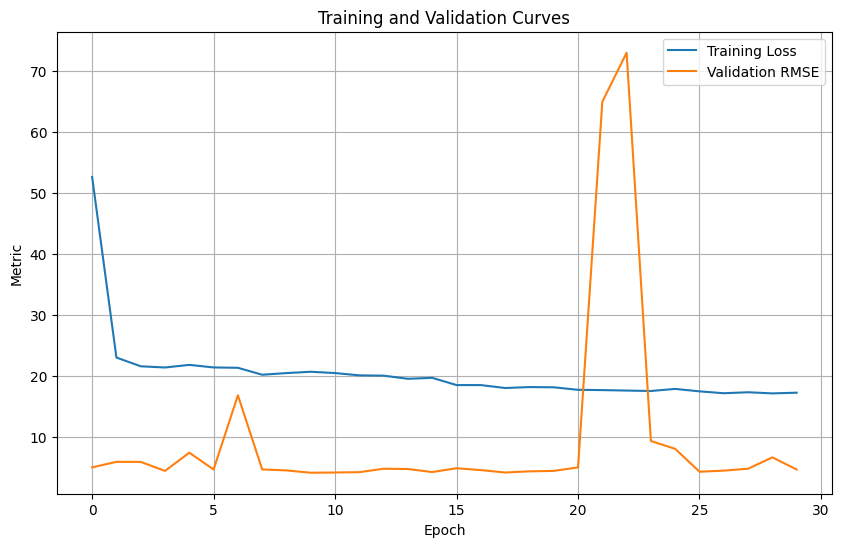

In [43]:
print("Model ID after fine-tuning on new data and before training:", id(model))
# Train on old data
model.train_model(
    best_params = model.best_params_old,
    max_epochs=200,
    patience=20,
    batch_size=256,
    virtual_batch_size=256
)

In [44]:
print("\nEvaluating on Validation Data after Training on Old Data:")
# Assuming predictions and true labels are stored in these variables
y_train_pred = model.model.predict(model.X_train)
y_val_pred = model.model.predict(model.X_val)

# Call the display_metrics function
model.display_metrics(model.y_train, y_train_pred, model.y_val, y_val_pred)


Evaluating on Validation Data after Training on Old Data:
Training Set Metrics:
  MAE: 3.1112
  MSE: 17.5951
  RMSE: 4.1947
  R²: 0.9346

Validation Set Metrics:
  MAE: 2.9665
  MSE: 17.1053
  RMSE: 4.1359
  R²: 0.9192
Best params old: {'n_d': 16, 'n_a': 16, 'n_steps': 5, 'gamma': 1.0, 'optimizer_params': {'lr': 0.05}, 'lambda_sparse': 0.005, 'mask_type': 'entmax', 'clip_value': 10}
Best params new: {}


### New

In [45]:
model.prepare_new_data()


Transforming data with shape: (13694, 44)
Transforming data with shape: (3424, 44)
Transforming data with shape: (390, 44)


In [ ]:
# ## Tune New Data
# Print model ID before fine-tuning on new data
print("Model ID before fine-tuning on new data:", id(model))
# Tune on new data
model.best_params_new = model.tune_model(patience = 10, max_epochs = 20)

In [46]:
model.best_params_new = {'n_d': 32,
                         'n_a': 16,
                         'n_steps': 5,
                         'gamma': 1.5,
                         'optimizer_params': {'lr': 0.05},
                         'lambda_sparse': 0.01,
                         'mask_type': 'entmax'}
# {'n_d': 32,
#  'n_a': 16,
#  'n_steps': 5,
#  'gamma': 1.5,
#  'lambda_sparse': 0.01,
#  'mask_type': 'entmax',
#  'optimizer_params': {'lr': 0.05}}

model.best_params_new

{'n_d': 32,
 'n_a': 16,
 'n_steps': 5,
 'gamma': 1.5,
 'optimizer_params': {'lr': 0.05},
 'lambda_sparse': 0.01,
 'mask_type': 'entmax'}

Model ID after fine-tuning on new data and before training: 2586251890464
Models params: {'cat_dims': [], 'cat_emb_dim': [], 'cat_idxs': [], 'clip_value': 10, 'device_name': 'auto', 'epsilon': 1e-15, 'gamma': 1.5, 'grouped_features': [], 'input_dim': 16, 'lambda_sparse': 0.01, 'mask_type': 'entmax', 'momentum': 0.02, 'n_a': 16, 'n_d': 32, 'n_indep_decoder': 1, 'n_independent': 4, 'n_shared': 4, 'n_shared_decoder': 1, 'n_steps': 5, 'optimizer_fn': <class 'torch.optim.adam.Adam'>, 'optimizer_params': {'lr': 0.05}, 'output_dim': 1, 'scheduler_fn': <class 'torch.optim.lr_scheduler.StepLR'>, 'scheduler_params': {'step_size': 15, 'gamma': 0.5}, 'seed': 42, 'verbose': 1}
epoch 0  | loss: 68.2128 | val_0_rmse: 11.86796|  0:00:20s
epoch 1  | loss: 22.85058| val_0_rmse: 10.08315|  0:00:40s
epoch 2  | loss: 21.03433| val_0_rmse: 7.25444 |  0:00:57s
epoch 3  | loss: 21.79461| val_0_rmse: 8.02846 |  0:01:11s
epoch 4  | loss: 20.81565| val_0_rmse: 7.95357 |  0:01:30s
epoch 5  | loss: 20.71997| val_0

c:\git\CampTvNew\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Training complete. Best epoch: 15
Best validation RMSE: 5.23197712969657
Best Params: {'n_d': 32, 'n_a': 16, 'n_steps': 5, 'gamma': 1.5, 'optimizer_params': {'lr': 0.05}, 'lambda_sparse': 0.01, 'mask_type': 'entmax'}


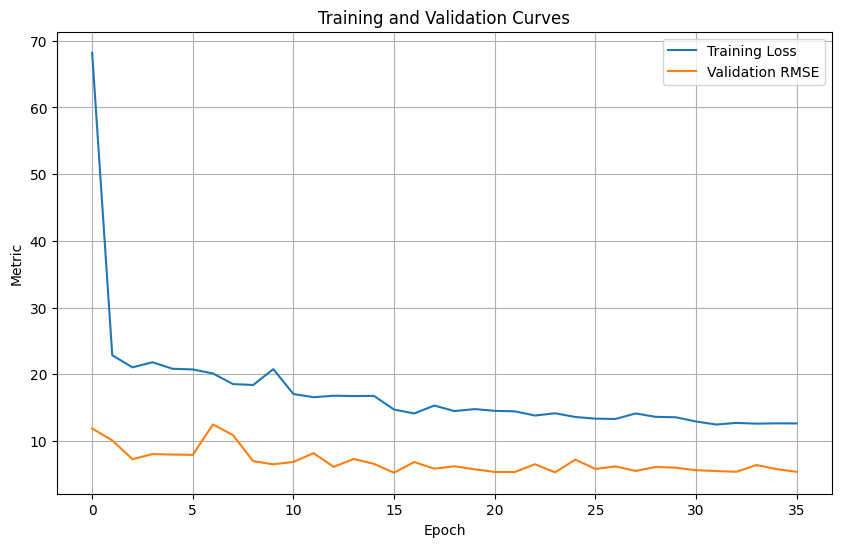

In [47]:
print("Model ID after fine-tuning on new data and before training:", id(model))
# Train on new data
model.train_model(
    best_params = model.best_params_new,
    max_epochs=150,
    patience=20,
    batch_size=128,
    virtual_batch_size=128
)

In [48]:
print("\nEvaluating on Validation Data after Training on New Data:")
# Assuming predictions and true labels are stored in these variables
y_train_pred = model.model.predict(model.X_train)
y_val_pred = model.model.predict(model.X_val)

# Call the display_metrics function
model.display_metrics(model.y_train, y_train_pred, model.y_val, y_val_pred)


Evaluating on Validation Data after Training on New Data:
Training Set Metrics:
  MAE: 2.9736
  MSE: 13.6889
  RMSE: 3.6999
  R²: 0.9287

Validation Set Metrics:
  MAE: 3.8652
  MSE: 27.3736
  RMSE: 5.2320
  R²: 0.8861
Best params old: {'n_d': 16, 'n_a': 16, 'n_steps': 5, 'gamma': 1.0, 'optimizer_params': {'lr': 0.05}, 'lambda_sparse': 0.005, 'mask_type': 'entmax', 'clip_value': 10}
Best params new: {'n_d': 32, 'n_a': 16, 'n_steps': 5, 'gamma': 1.5, 'optimizer_params': {'lr': 0.05}, 'lambda_sparse': 0.01, 'mask_type': 'entmax'}


'Feature Importances with Feature Names:'

{'npo1_grp_daynight': 0.1998587035447626,
 'npo1_grp_primetime': 0.5036151475345675,
 'npo2_grp_daynight': 0.0015039990202515674,
 'npo2_grp_primetime': 2.807926974904256e-05,
 'npo3_grp_daynight': 0.0,
 'npo3_grp_primetime': 0.04992061256652927,
 'regio_grp_daynight': 0.02637783637210948,
 'regio_grp_primetime': 0.0,
 'timef_olympic_period_overlap': 0.0,
 'timef_football_period_overlap': 0.01776400268174144,
 'timef_duration_days': 0.15872144262761032,
 'timef_start_year': 4.671680590089345e-06,
 'timef_start_week': 0.0,
 'alcohol_kansspelen': 0.02641532082233336,
 'is_olympic_period': 0.00019257561104299778,
 'is_football_period': 0.015597608268712338}

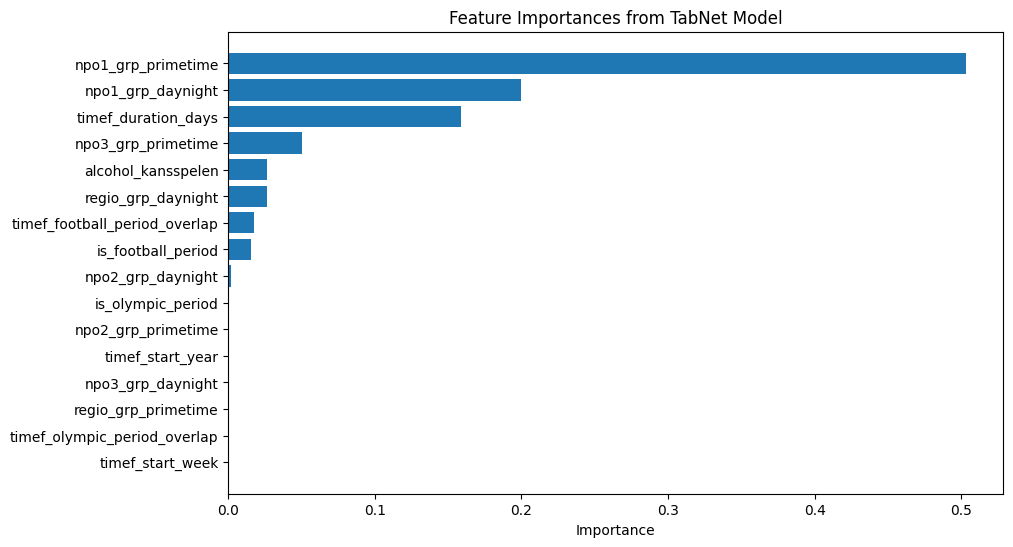

In [49]:
model.show_feature_importance()

In [ ]:
residuals = model.y_val.flatten() - y_val_pred.flatten()

# Scatter plot of residuals
plt.figure(figsize=(10, 6))
plt.scatter(y_val_pred, residuals, alpha=0.6)
plt.axhline(0, color='red', linestyle='--', linewidth=1)  # Reference line for zero residual
plt.title("Residuals vs. Predicted Values")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.show();

In [51]:
model.predict_and_export_to_excel()

Using: <class 'pytorch_tabnet.tab_model.TabNetRegressor'>
Test Set Metrics:
  MAE: 2.8990
  MSE: 13.3762
  RMSE: 3.6573
  R²: 0.8885
Excel file saved as test_predictions.xlsx


In [ ]:
model.best_model

In [ ]:
type(model)

In [52]:
model.model.save_model("./model_nn")

Successfully saved model at ./model_nn.zip


'./model_nn.zip'

In [57]:
from openpyxl import load_workbook
from openpyxl.styles import PatternFill


def color_residual_columns(file_path, output_path):
    # Load the workbook and select the active worksheet
    wb = load_workbook(file_path)
    ws = wb.active

    # Define colors for different thresholds
    light_red = PatternFill(start_color="FFC7CE", end_color="FFC7CE", fill_type="solid")
    medium_red = PatternFill(start_color="FF5733", end_color="FF5733", fill_type="solid")
    dark_red = PatternFill(start_color="B22222", end_color="B22222", fill_type="solid")
    light_blue = PatternFill(start_color="ADD8E6", end_color="ADD8E6", fill_type="solid")
    medium_blue = PatternFill(start_color="6495ED", end_color="6495ED", fill_type="solid")
    dark_blue = PatternFill(start_color="00008B", end_color="00008B", fill_type="solid")

    # Columns to apply coloring
    columns_to_color = ["residual_lgb", "residual_nn", "residual_cat"]

    # Identify column indices for the specified columns
    header_row = ws[1]
    col_indices = {cell.value: idx for idx, cell in enumerate(header_row, start=1)}
    target_indices = [col_indices[col] for col in columns_to_color if col in col_indices]

    # Iterate over rows and apply coloring
    for row in ws.iter_rows(min_row=2, max_col=max(target_indices), max_row=ws.max_row):
        for col_idx in target_indices:
            cell = row[col_idx - 1]  # Adjusting for 0-based index
            if cell.value is not None:
                if cell.value >= 8:
                    cell.fill = dark_red
                elif cell.value >= 5:
                    cell.fill = medium_red
                elif cell.value >= 2:
                    cell.fill = light_red
                elif cell.value <= -8:
                    cell.fill = dark_blue
                elif cell.value <= -5:
                    cell.fill = medium_blue
                elif cell.value <= -2:
                    cell.fill = PatternFill(start_color="FFA8D0E6", end_color="FFA8D0E6", fill_type="solid")

    # Save the workbook to the output path
    wb.save(output_path)
    print(f"Coloring applied and saved to {output_path}")

# Load DataFrames
df1_nn = pd.read_excel("test_predictions_nn.xlsx")
df2_lgb = pd.read_excel("test_predictions_lgb.xlsx")[['flight_id', 'prediction', 'residual']]
df3_cat = pd.read_excel("test_predictions_cat.xlsx")[['flight_id', 'prediction', 'residual']]

# Rename columns for clarity
df2_lgb = df2_lgb.rename(columns={'prediction': 'prediction_lgb', 'residual': 'residual_lgb'})
df3_cat = df3_cat.rename(columns={'prediction': 'prediction_cat', 'residual': 'residual_cat'})

# Merge all DataFrames on 'flight_id'
merged_df = (
    df1_nn
    .merge(df2_lgb, on='flight_id', how='left')
    .merge(df3_cat, on='flight_id', how='left')
)

# Save or display the merged DataFrame
merged_df.to_excel("merged_predictions.xlsx", index=False)
color_residual_columns("merged_predictions.xlsx", "merged_predictions_coloured.xlsx")

Coloring applied and saved to merged_predictions_coloured.xlsx
